
# ANN para predecir la calidad del syngas

## Objetivo de la práctica

En este notebook vamos a construir una **red neuronal artificial (RNA) de regresión multisalida**.

- **Hoja1** se usa para desarrollar la ANN:
  - 60 % entrenamiento
  - 20 % validación
  - 20 % prueba (test)
- **Hoja2** se usa al final como **validación externa**.
- En la validación externa **NO se vuelve a entrenar la red**.

La RNA utilizará como entradas:

`C, H, O, Moisture, Ash, FC, VM, ER, T, SB`

y predecirá simultáneamente:

`H2, CO, CO2, CH4, LHV`

> Idea clave: entrenar significa **aprender los pesos** de la red.  
> Predecir significa usar esos pesos ya aprendidos sobre datos nuevos.



## 0. Preparación del entorno

Coloca este notebook y el archivo `base_datos_ANN.xlsx` **en la misma carpeta**.

Si alguna librería no está instalada, descomenta y ejecuta la siguiente línea una sola vez.


In [4]:

# Ejecutar solamente si faltan librerías:
# %pip install tensorflow pandas scikit-learn openpyxl matplotlib joblib



## 1. Importar las librerías

Cada librería tiene una función:

- `pandas`: leer el Excel y trabajar con tablas.
- `numpy`: operaciones numéricas.
- `scikit-learn`: dividir y normalizar los datos, y calcular métricas.
- `tensorflow / keras`: construir y entrenar la ANN.
- `matplotlib`: representar los resultados.
- `joblib`: guardar los escaladores.


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model

# Para que el ejemplo sea lo más reproducible posible
SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)



## 2. ZONA DE CONFIGURACIÓN — esta es la parte que normalmente se modifica

Esta celda es deliberadamente importante.

Si en otro problema queremos:

- añadir o quitar **entradas**, modificamos `ENTRADAS`;
- añadir o quitar **salidas**, modificamos `SALIDAS`;
- cambiar el tamaño de la capa oculta, modificamos `NEURONAS_OCULTAS`.

El resto del notebook utiliza `len(ENTRADAS)` y `len(SALIDAS)`, por lo que la capa de entrada y la capa de salida se adaptan automáticamente.


In [8]:

# ============================================================
# ZONA PARA MODIFICAR
# ============================================================

ARCHIVO = "base_datos_ANN.xlsx"

HOJA_DESARROLLO = "Hoja1"
HOJA_EXTERNA = "Hoja2"

# Variables que ENTRAN en la red
ENTRADAS = [
    "C", "H", "O", "Moisture", "Ash",
    "FC", "VM", "ER", "T", "SB"
]

# Variables que la red debe PREDECIR
SALIDAS = [
    "H2", "CO", "CO2", "CH4", "LHV"
]

# Arquitectura básica de la ANN
NEURONAS_OCULTAS = 10
ACTIVACION_OCULTA = "tanh"

# Entrenamiento
EPOCAS_MAXIMAS = 400
BATCH_SIZE = 16
PACIENCIA = 30

print("Número de entradas:", len(ENTRADAS))
print("Número de salidas:", len(SALIDAS))


Número de entradas: 10
Número de salidas: 5



## 3. Leer la Hoja 1

Primero cargamos los datos destinados al desarrollo de la ANN.

`str.strip()` elimina espacios accidentales al inicio o al final de los nombres de las columnas.  
Esto es útil porque, por ejemplo, Excel puede contener `H2 ` en lugar de `H2`.


In [10]:

df = pd.read_excel(ARCHIVO, sheet_name=HOJA_DESARROLLO)

# Limpiar los nombres de columnas
df.columns = df.columns.str.strip()

print("Dimensión de Hoja1:", df.shape)
display(df.head())

# Comprobar que todas las columnas solicitadas existen
columnas_necesarias = ENTRADAS + SALIDAS
faltantes = [col for col in columnas_necesarias if col not in df.columns]

if faltantes:
    raise ValueError(f"Faltan estas columnas en {HOJA_DESARROLLO}: {faltantes}")

print("Todas las entradas y salidas están disponibles.")


Dimensión de Hoja1: (274, 15)


,C,H,O,Moisture,Ash,FC,VM,ER,T,SB,H2,CO,CO2,CH4,LHV
0,52.739560,5.316635,47.878969,18.947361,3.973109,11.921704,84.105187,0.205428,840.284925,0.975622,13.452958,9.013446,17.890080,1.501653,3.129451
1,46.299215,5.427115,38.403640,18.396280,1.699360,22.483897,75.816743,0.298031,825.066276,0.832678,15.448901,15.222508,12.855392,1.623760,4.173287
2,53.047644,5.162435,39.324922,18.649910,3.977237,19.972763,76.050000,0.217733,651.840567,0.199908,11.722532,16.980944,12.390927,2.391927,4.268252
3,52.051654,6.342187,41.883737,16.374824,2.461262,18.478542,79.060197,0.217745,817.100740,0.114530,14.936329,20.690198,9.009353,3.031974,5.313231
4,52.649989,5.904155,43.303691,16.184143,1.230006,16.127930,82.642064,0.262067,759.179347,0.030818,10.742744,20.649238,9.417472,2.385689,4.623745


Todas las entradas y salidas están disponibles.



## 4. Separar entradas `X` y salidas `y`

En aprendizaje supervisado:

- `X` contiene la información que entregamos a la red;
- `y` contiene los valores que queremos que la red aprenda a predecir.

Aquí tenemos **10 entradas** y **5 salidas**.


In [12]:

X = df[ENTRADAS].copy()
y = df[SALIDAS].copy()

print("X:", X.shape)
print("y:", y.shape)


X: (274, 10)
y: (274, 5)



## 5. División 60 % / 20 % / 20 %

La Hoja 1 se divide en tres conjuntos independientes:

**Entrenamiento:** la red ajusta sus pesos con estos datos.

**Validación:** se observa durante el entrenamiento para decidir cuándo detenerlo, pero no se utiliza para actualizar directamente los pesos.

**Prueba (test):** se reserva hasta el final para comprobar cómo generaliza el modelo con datos que no utilizó para aprender.

Primero separamos 60 % para entrenamiento y 40 % temporal.  
Después dividimos ese 40 % en dos partes iguales: 20 % validación y 20 % test.


In [14]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=SEMILLA
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEMILLA
)

n_total = len(df)

print(f"Total:         {n_total}")
print(f"Entrenamiento: {len(X_train)} ({len(X_train)/n_total:.1%})")
print(f"Validación:    {len(X_val)} ({len(X_val)/n_total:.1%})")
print(f"Test:          {len(X_test)} ({len(X_test)/n_total:.1%})")


Total:         274
Entrenamiento: 164 (59.9%)
Validación:    55 (20.1%)
Test:          55 (20.1%)



## 6. Normalización 0–1

Las variables tienen escalas muy diferentes. Por ejemplo, `T` puede estar en centenas mientras `ER` es mucho menor que 1.

Por eso usamos `MinMaxScaler`, que transforma cada variable aproximadamente al intervalo 0–1.

### Muy importante: evitar fuga de información

Los escaladores se **ajustan solamente con entrenamiento**:

```python
scaler.fit(datos_de_entrenamiento)
```

Después se aplican a validación, test y validación externa usando solamente:

```python
scaler.transform(...)
```

No debemos volver a hacer `fit` con los datos externos.


In [16]:

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# FIT solamente con entrenamiento
X_train_s = scaler_X.fit_transform(X_train)
y_train_s = scaler_y.fit_transform(y_train)

# VALIDACIÓN y TEST solamente se transforman
X_val_s = scaler_X.transform(X_val)
y_val_s = scaler_y.transform(y_val)

X_test_s = scaler_X.transform(X_test)
y_test_s = scaler_y.transform(y_test)

print("Normalización terminada.")


Normalización terminada.



## 7. Construir la RNA

Usaremos una red *feed-forward* muy sencilla:

**10 entradas → 10 neuronas ocultas → 5 salidas**

La capa oculta utiliza `tanh`.

La capa final utiliza activación `linear`, apropiada para un problema de regresión.

Observa que no escribimos manualmente `10` para las entradas ni `5` para las salidas:

```python
Input(shape=(len(ENTRADAS),))
Dense(len(SALIDAS))
```

Por eso el código se adapta si posteriormente cambiamos las listas.


In [18]:

modelo = Sequential([
    Input(shape=(len(ENTRADAS),)),
    Dense(NEURONAS_OCULTAS, activation=ACTIVACION_OCULTA),
    Dense(len(SALIDAS), activation="linear")
])

modelo.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)


## 8. Entrenar la ANN


Ahora sí aparece `modelo.fit(...)`.

**Esta es la instrucción que hace que la red aprenda.**

Usamos:

- optimizador Adam;
- batch de 16;
- máximo 400 épocas;
- *early stopping* con paciencia de 30 épocas.

El *early stopping* detiene el entrenamiento cuando el error de validación deja de mejorar y recupera los mejores pesos encontrados.


In [20]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=PACIENCIA,
    restore_best_weights=True
)

historial = modelo.fit(
    X_train_s,
    y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=EPOCAS_MAXIMAS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=0
)

print("Épocas realmente ejecutadas:", len(historial.history["loss"]))


Épocas realmente ejecutadas: 400



## 9. Curva de aprendizaje

Comparamos el error de entrenamiento con el error de validación.

Una separación muy grande entre ambas curvas puede ser una señal de sobreajuste.


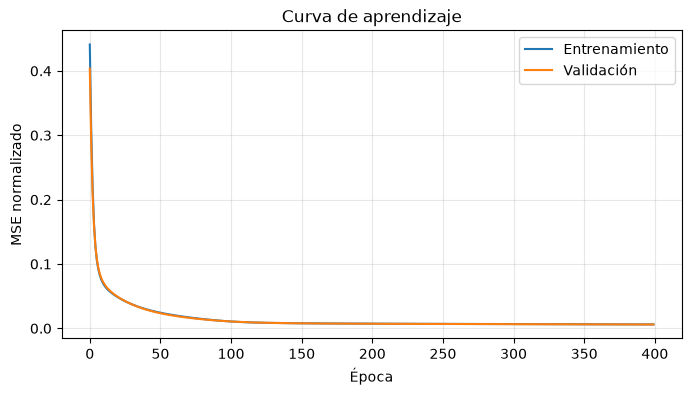

In [22]:

plt.figure(figsize=(8, 4))
plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("MSE normalizado")
plt.title("Curva de aprendizaje")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 10. Evaluar con el conjunto de prueba

El test se utiliza **después del entrenamiento**.

Primero la ANN predice los valores normalizados y después usamos `inverse_transform()` para volver a las unidades originales.


In [24]:

# Predicción en TEST
y_test_pred_s = modelo.predict(X_test_s, verbose=0)

# Volver a unidades originales
y_test_pred = scaler_y.inverse_transform(y_test_pred_s)
y_test_real = y_test.to_numpy()

# Métricas globales sobre los valores normalizados
mse_global_test = mean_squared_error(y_test_s, y_test_pred_s)
r_global_test = np.corrcoef(y_test_s.ravel(), y_test_pred_s.ravel())[0, 1]

print(f"MSE global normalizado (test): {mse_global_test:.5f}")
print(f"R global normalizado   (test): {r_global_test:.4f}")


MSE global normalizado (test): 0.00994
R global normalizado   (test): 0.8890



### Métricas de cada salida

Además del valor global, conviene estudiar cada variable de salida por separado.


In [26]:

def calcular_metricas(y_real, y_pred, nombres_salidas):
    filas = []

    for i, nombre in enumerate(nombres_salidas):
        real = y_real[:, i]
        pred = y_pred[:, i]

        mse = mean_squared_error(real, pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(real, pred)
        r = np.corrcoef(real, pred)[0, 1]

        filas.append({
            "Salida": nombre,
            "MSE": mse,
            "RMSE": rmse,
            "MAE": mae,
            "R": r
        })

    return pd.DataFrame(filas)

metricas_test = calcular_metricas(
    y_test_real,
    y_test_pred,
    SALIDAS
)

display(metricas_test)


,Salida,MSE,RMSE,MAE,R
0,H2,1.626090,1.275182,1.039671,0.919586
1,CO,1.894859,1.376539,1.163813,0.918320
2,CO2,0.781138,0.883820,0.683243,0.961002
3,CH4,0.274595,0.524018,0.409395,0.763555
4,LHV,0.147766,0.384404,0.314409,0.867950



## 11. Gráfica experimental vs. predicción en test

La línea discontinua representa la predicción ideal:

\[
y_{\mathrm{predicho}} = y_{\mathrm{real}}
\]

Cuanto más cerca estén los puntos de esa diagonal, mejor es la predicción.


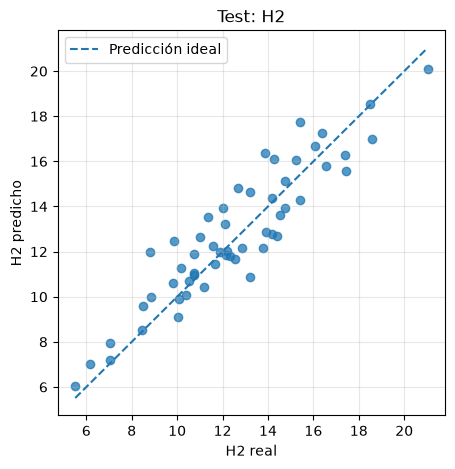

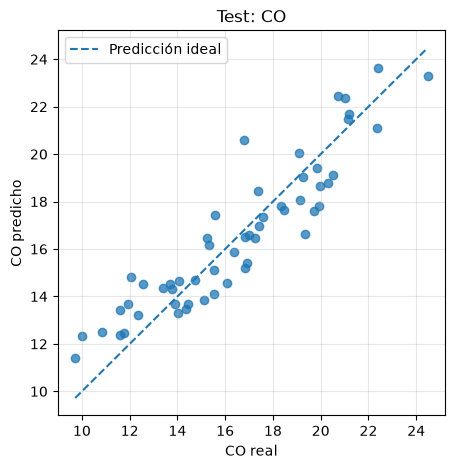

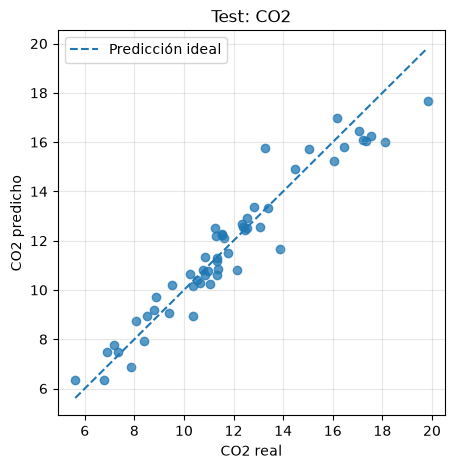

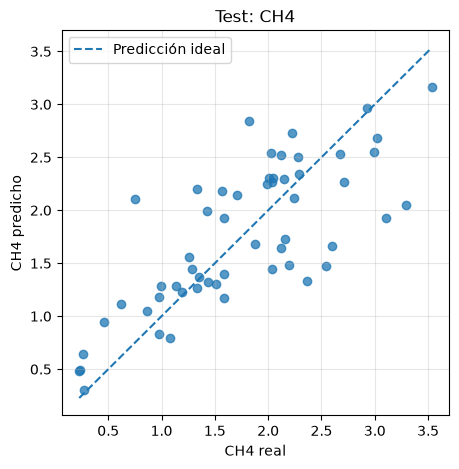

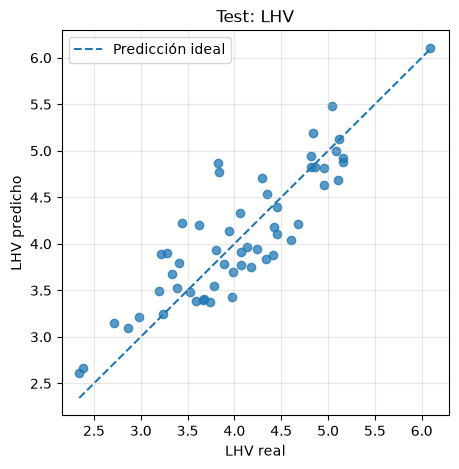

In [28]:

for i, salida in enumerate(SALIDAS):
    real = y_test_real[:, i]
    pred = y_test_pred[:, i]

    minimo = min(real.min(), pred.min())
    maximo = max(real.max(), pred.max())

    plt.figure(figsize=(5, 5))
    plt.scatter(real, pred, alpha=0.75)
    plt.plot([minimo, maximo], [minimo, maximo], "--", label="Predicción ideal")
    plt.xlabel(f"{salida} real")
    plt.ylabel(f"{salida} predicho")
    plt.title(f"Test: {salida}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()



## 12. Guardar lo aprendido

Una ANN entrenada no es solamente su arquitectura: también contiene los **pesos aprendidos**.

Además, para utilizarla correctamente con datos nuevos necesitamos conservar los mismos escaladores utilizados durante el entrenamiento.

Guardaremos:

- `modelo_ann_syngas.keras`
- `scaler_X.pkl`
- `scaler_y.pkl`

Esto nos permite cerrar el notebook y utilizar posteriormente la ANN sin entrenarla otra vez.


In [30]:

modelo.save("modelo_ann_syngas.keras")
joblib.dump(scaler_X, "scaler_X.pkl")
joblib.dump(scaler_y, "scaler_y.pkl")

print("Modelo y escaladores guardados.")


Modelo y escaladores guardados.



# 13. VALIDACIÓN EXTERNA — Hoja 2

## Desde este punto NO entrenamos la red

Para dejarlo completamente claro, vamos a **cargar desde el disco** la ANN que ya aprendió con Hoja1.

En esta sección no debe aparecer:

```python
modelo.fit(...)
```

Solamente aparecen:

```python
load_model(...)
transform(...)
predict(...)
```

Esa diferencia separa conceptualmente **entrenamiento** de **uso del modelo aprendido**.


In [32]:

# Cargar la ANN YA ENTRENADA
modelo_aprendido = load_model("modelo_ann_syngas.keras")

# Cargar EXACTAMENTE los mismos escaladores del entrenamiento
scaler_X_aprendido = joblib.load("scaler_X.pkl")
scaler_y_aprendido = joblib.load("scaler_y.pkl")

print("ANN y escaladores cargados. No se ha realizado ningún entrenamiento.")


ANN y escaladores cargados. No se ha realizado ningún entrenamiento.



## 14. Leer la Hoja 2 y predecir

Hoja2 representa datos externos que la ANN no utilizó para ajustar sus pesos.

Las entradas se normalizan con `transform()`, **nunca con `fit_transform()`**.


In [34]:

df_ext = pd.read_excel(ARCHIVO, sheet_name=HOJA_EXTERNA)
df_ext.columns = df_ext.columns.str.strip()

faltantes_ext = [col for col in ENTRADAS if col not in df_ext.columns]
if faltantes_ext:
    raise ValueError(f"Faltan estas entradas en {HOJA_EXTERNA}: {faltantes_ext}")

X_ext = df_ext[ENTRADAS].copy()

# ATENCIÓN: solo TRANSFORM, no FIT
X_ext_s = scaler_X_aprendido.transform(X_ext)

# Usar la ANN ya aprendida
y_ext_pred_s = modelo_aprendido.predict(X_ext_s, verbose=0)

# Recuperar unidades originales
y_ext_pred = scaler_y_aprendido.inverse_transform(y_ext_pred_s)

print("Predicciones externas calculadas:", y_ext_pred.shape)


Predicciones externas calculadas: (26, 5)



## 15. Comparar Hoja 2 con los valores experimentales

En este Excel, Hoja2 también contiene los valores reales de `H2`, `CO`, `CO2`, `CH4` y `LHV`, por lo que podemos calcular métricas externas.

En una aplicación real, si esos valores todavía fueran desconocidos, la ANN igualmente podría predecirlos, pero no podríamos calcular el error hasta disponer de las mediciones reales.


In [36]:

if all(col in df_ext.columns for col in SALIDAS):
    y_ext_real = df_ext[SALIDAS].to_numpy()

    metricas_externas = calcular_metricas(
        y_ext_real,
        y_ext_pred,
        SALIDAS
    )

    display(metricas_externas)

    # R y MSE globales en escala normalizada para comparación
    y_ext_real_s = scaler_y_aprendido.transform(df_ext[SALIDAS])
    mse_global_ext = mean_squared_error(y_ext_real_s, y_ext_pred_s)
    r_global_ext = np.corrcoef(y_ext_real_s.ravel(), y_ext_pred_s.ravel())[0, 1]

    print(f"MSE global normalizado (externa): {mse_global_ext:.5f}")
    print(f"R global normalizado   (externa): {r_global_ext:.4f}")
else:
    print("Hoja2 no contiene todas las salidas reales.")
    print("Se pueden obtener predicciones, pero no calcular el error externo.")


,Salida,MSE,RMSE,MAE,R
0,H2,1.739399,1.318863,1.119590,0.933985
1,CO,1.850973,1.360505,1.134478,0.941092
2,CO2,0.869613,0.932530,0.596042,0.962678
3,CH4,0.297253,0.545210,0.416259,0.835632
4,LHV,0.140388,0.374684,0.330288,0.926451


MSE global normalizado (externa): 0.01037
R global normalizado   (externa): 0.9150



## 16. Gráficas de validación externa

Ahora comparamos, muestra a muestra, el valor experimental con el predicho por la ANN.


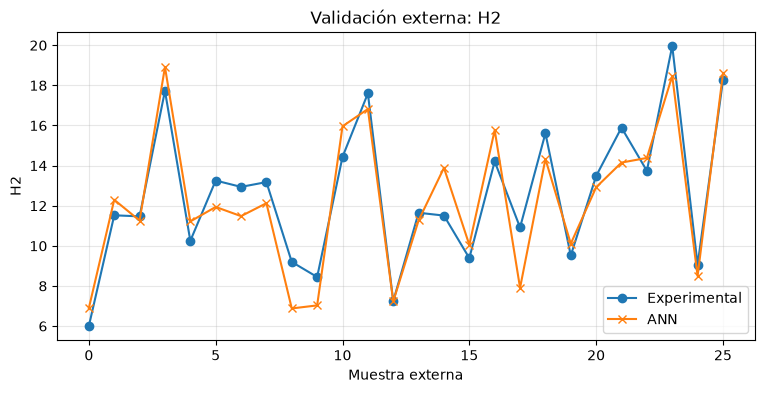

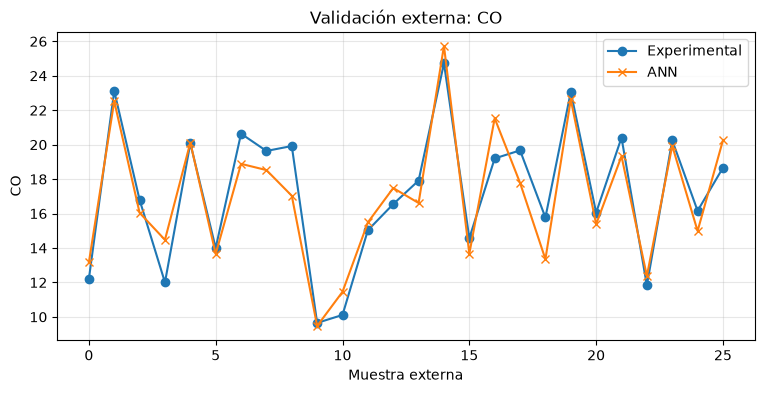

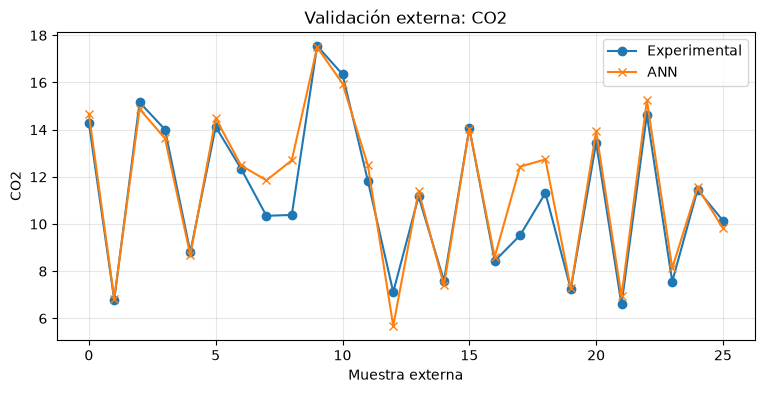

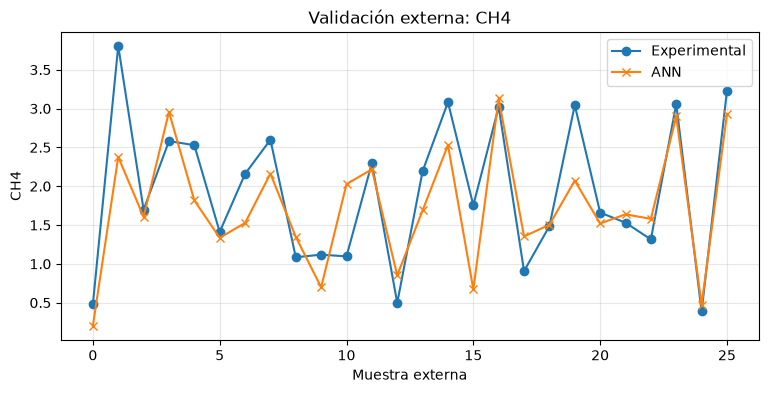

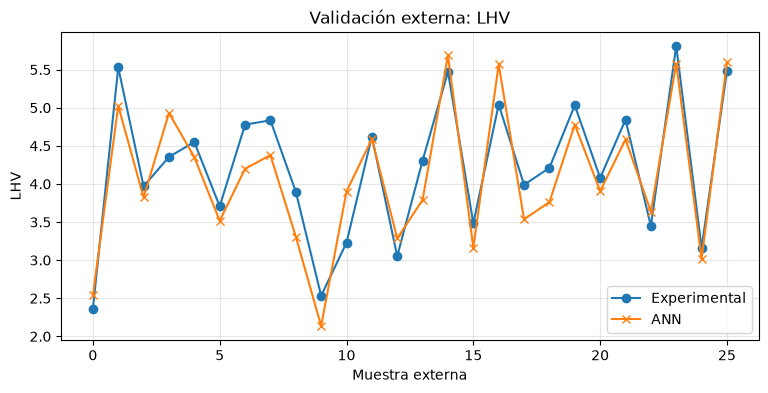

In [38]:

if all(col in df_ext.columns for col in SALIDAS):
    for i, salida in enumerate(SALIDAS):
        plt.figure(figsize=(9, 4))
        plt.plot(df_ext[salida].to_numpy(), marker="o", label="Experimental")
        plt.plot(y_ext_pred[:, i], marker="x", label="ANN")
        plt.xlabel("Muestra externa")
        plt.ylabel(salida)
        plt.title(f"Validación externa: {salida}")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()



## 17. Guardar las predicciones de Hoja 2

Creamos un nuevo archivo Excel con los datos externos y las columnas predichas por la ANN.


In [40]:

resultado_externo = df_ext.copy()

for i, salida in enumerate(SALIDAS):
    resultado_externo[f"{salida}_ANN"] = y_ext_pred[:, i]

    if salida in df_ext.columns:
        resultado_externo[f"{salida}_error"] = (
            resultado_externo[f"{salida}_ANN"] - resultado_externo[salida]
        )

resultado_externo.to_excel(
    "validacion_externa_predicciones.xlsx",
    index=False
)

display(resultado_externo.head())

print("Archivo creado: validacion_externa_predicciones.xlsx")


,C,H,O,Moisture,Ash,FC,VM,ER,T,SB,...,H2_ANN,H2_error,CO_ANN,CO_error,CO2_ANN,CO2_error,CH4_ANN,CH4_error,LHV_ANN,LHV_error
0,53.358630,4.225418,46.097466,24.768948,1.895790,20.192278,77.911932,0.408582,806.691516,0.579665,...,6.901424,0.894357,13.158112,0.957880,14.673525,0.383539,0.200435,-0.277543,2.536459,0.174992
1,52.703954,6.994685,42.386944,6.226081,1.778144,20.965448,77.256408,0.340882,711.191261,0.119024,...,12.297014,0.774499,22.520247,-0.596562,6.841443,0.053290,2.376676,-1.429281,5.025648,-0.502811
2,49.652125,4.659980,47.187745,19.727082,4.166771,20.257670,75.575559,0.239928,765.699734,0.451215,...,11.259244,-0.210349,16.042673,-0.748326,14.877458,-0.281473,1.604773,-0.092271,3.822231,-0.145814
3,51.431675,5.949482,39.057051,12.434225,2.303544,13.680344,84.016112,0.192329,758.249554,0.786941,...,18.913857,1.186797,14.471415,2.471486,13.628746,-0.377532,2.957149,0.376439,4.930014,0.575176
4,47.094273,5.763466,38.488295,6.284177,2.270328,22.225672,75.504000,0.387227,745.058896,0.376469,...,11.217470,0.967976,20.122032,0.043457,8.683328,-0.130871,1.816559,-0.711629,4.351551,-0.197864


Archivo creado: validacion_externa_predicciones.xlsx



# 18. ¿Qué debe cambiar en otro problema?

### Si añade una nueva entrada

Por ejemplo, si el Excel incorpora una columna llamada `Pressure`, basta con:

```python
ENTRADAS = [
    "C", "H", "O", "Moisture", "Ash",
    "FC", "VM", "ER", "T", "SB", "Pressure"
]
```

La línea:

```python
Input(shape=(len(ENTRADAS),))
```

detectará automáticamente que ahora existen 11 entradas.

### Si añade una nueva salida

Por ejemplo, si quiere predecir además `Tar`:

```python
SALIDAS = ["H2", "CO", "CO2", "CH4", "LHV", "Tar"]
```

La línea:

```python
Dense(len(SALIDAS), activation="linear")
```

creará automáticamente 6 neuronas de salida.

### Si quiere hacer una ANN más compleja

Puede añadir otra capa oculta:

```python
modelo = Sequential([
    Input(shape=(len(ENTRADAS),)),
    Dense(20, activation="tanh"),
    Dense(10, activation="tanh"),
    Dense(len(SALIDAS), activation="linear")
])
```

Primero conviene entender bien la ANN de una sola capa oculta antes de aumentar la complejidad.



# 19. Resumen conceptual

El flujo completo es:

**Hoja1 → dividir → normalizar → entrenar → validar → testear → guardar modelo**

y después:

**Hoja2 → cargar modelo → normalizar con los escaladores aprendidos → predecir → comparar**

La idea más importante es:

> **Hoja2 nunca debe modificar los pesos de la ANN.**

Si la red aprende otra vez con Hoja2, esos datos dejan de ser una validación externa.
